# 4.5.2 Combiner le texte et l'image : Voting et Stacking, Dataset 2 (extrait final, 60 000 images)

Le modèle texte (SVM, 4.2) et le modèle image (85 mesures + XGBoost, 4.1), combinés avec les deux
méthodes du cours :
- `VotingClassifier` (soft) : moyenne pondérée des probabilités, avec un poids `alpha` pour le texte ;
- `StackingClassifier` : une régression logistique apprend sur leurs probabilités, obtenues par
  validation croisée sur le train.

Un `ColumnTransformer` envoie le texte à un modèle et les 85 mesures à l'autre. Le SVM ne donne pas de
probabilités, `CalibratedClassifierCV` les calcule.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

from outils_4 import ARTEFACTS_60K, ARTEFACTS_DATASET_1, CLASSES, load_corpus_60k, load_image_features, save_probas

train, test = load_corpus_60k()
y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
y_train_num = LabelEncoder().fit(CLASSES).transform(y_train)  # xgboost veut des classes 0..5

# une seule table : les 85 mesures + le texte
X_train = load_image_features(train["filepath"]).reset_index(drop=True).assign(text=train["text"])
X_test = load_image_features(test["filepath"]).reset_index(drop=True).assign(text=test["text"])
MESURES = [c for c in X_train.columns if c != "text"]

modele_texte = make_pipeline(
    ColumnTransformer([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True), "text")]),
    CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=5000), cv=5))
modele_image = make_pipeline(
    ColumnTransformer([("mesures", "passthrough", MESURES)]),
    XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric="mlogloss"))

## 1. Stacking

In [2]:
stacking = StackingClassifier([("texte", modele_texte), ("image", modele_image)],
                              final_estimator=LogisticRegression(max_iter=2000, random_state=42),
                              cv=5, stack_method="predict_proba")
stacking.fit(X_train, y_train)

# les 2 modèles de base, que le stacking a ré-entraînés sur tout le train
probas_texte_test = stacking.named_estimators_["texte"].predict_proba(X_test)
probas_image_test = stacking.named_estimators_["image"].predict_proba(X_test)

## 2. Voting soft : le poids `alpha` choisi sur le train

Avec les probabilités du train obtenues par validation croisée, sans regarder le test.

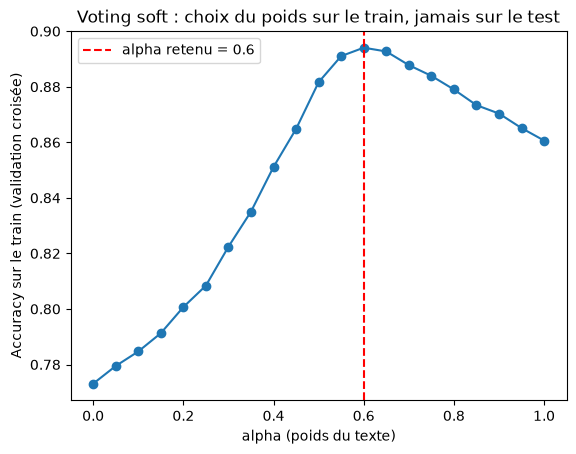

In [3]:
probas_texte_oof = cross_val_predict(modele_texte, X_train, y_train, cv=5, method="predict_proba", n_jobs=-1)
probas_image_oof = cross_val_predict(modele_image, X_train, y_train_num, cv=5, method="predict_proba", n_jobs=-1)


def best_alpha(p_texte, p_image):
    """le poids du texte qui marche le mieux sur le train"""
    alphas = np.round(np.arange(0, 1.01, 0.05), 2)
    accuracies = [accuracy_score(y_train, np.array(CLASSES)[(a * p_texte + (1 - a) * p_image).argmax(axis=1)])
                  for a in alphas]
    return alphas[int(np.argmax(accuracies))], alphas, accuracies


alpha, alphas, accuracies = best_alpha(probas_texte_oof, probas_image_oof)
plt.plot(alphas, accuracies, marker="o")
plt.axvline(alpha, color="red", linestyle="--", label=f"alpha retenu = {alpha}")
plt.xlabel("alpha (poids du texte)")
plt.ylabel("Accuracy sur le train (validation croisée)")
plt.title("Voting soft : choix du poids sur le train, jamais sur le test")
plt.legend()
plt.show()

voting = VotingClassifier([("texte", modele_texte), ("image", modele_image)], voting="soft",
                          weights=[alpha, 1 - alpha]).fit(X_train, y_train)

## 3. Comparaison

In [4]:
predictions = {
    "Texte seul": np.array(CLASSES)[probas_texte_test.argmax(axis=1)],
    "Image seule": np.array(CLASSES)[probas_image_test.argmax(axis=1)],
    f"Voting soft (alpha = {alpha})": voting.predict(X_test),
    "Stacking": stacking.predict(X_test),
}
facture = y_test == "invoice"
pd.DataFrame([{"configuration": nom, "accuracy": accuracy_score(y_test, p), "recall invoice": (p[facture] == "invoice").mean()}
              for nom, p in predictions.items()]).round(3)

,configuration,accuracy,recall invoice
0,Texte seul,0.867,0.890
1,Image seule,0.777,0.805
2,Voting soft (alpha = 0.6),0.891,0.902
3,Stacking,0.895,0.910


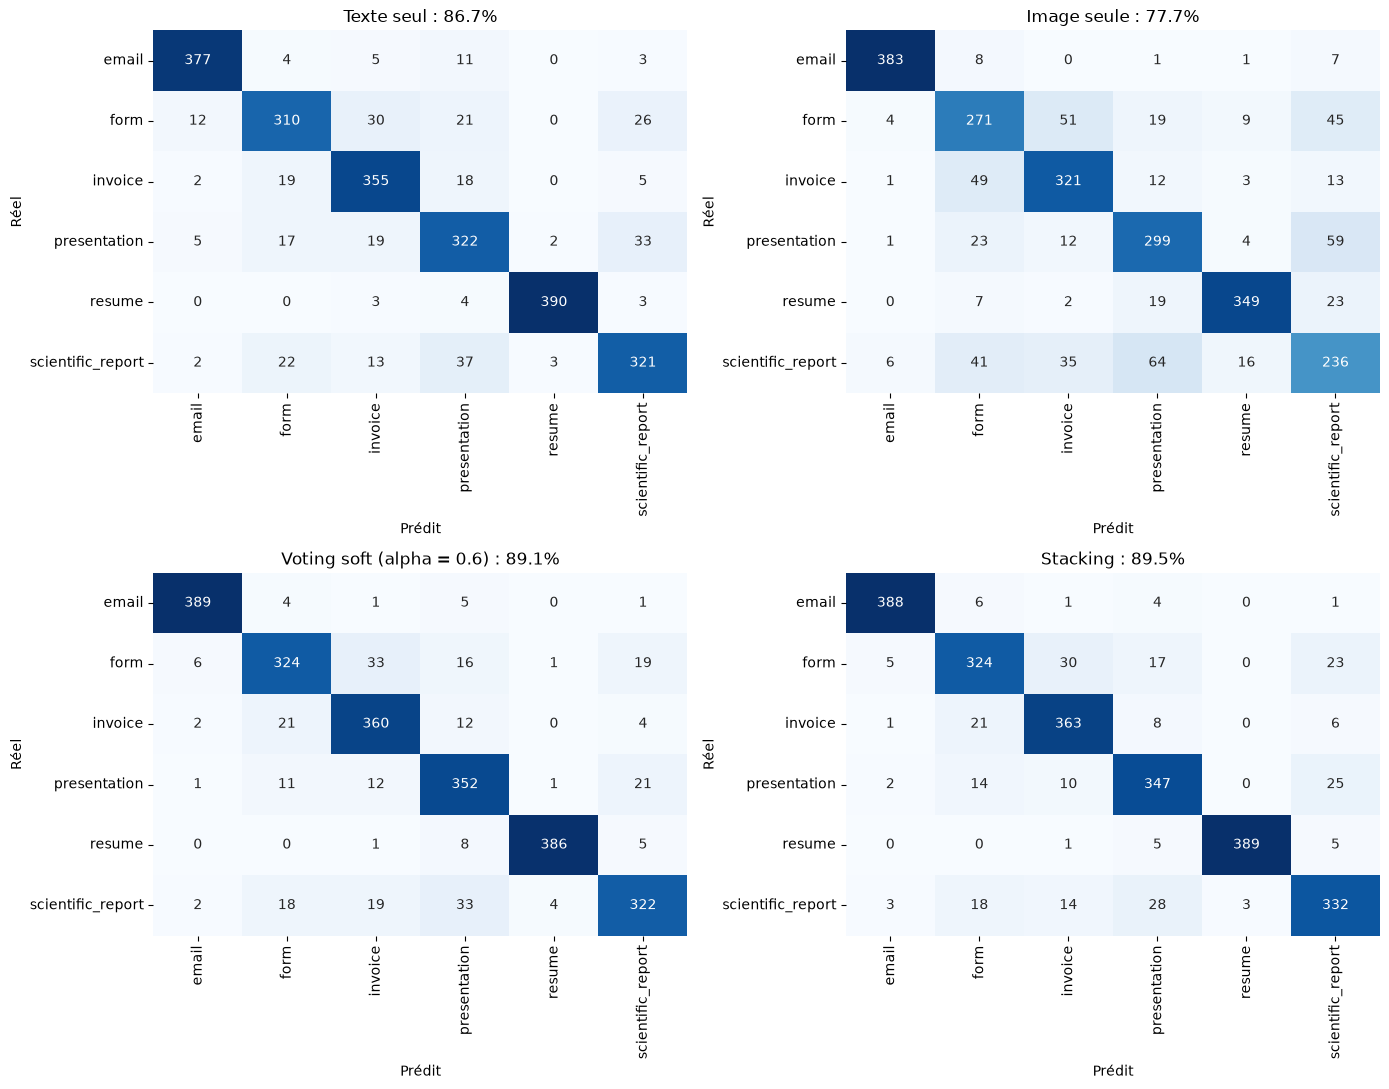

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (nom, p) in zip(axes.flat, predictions.items()):
    matrice = pd.crosstab(y_test, p, rownames=["Réel"], colnames=["Prédit"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{nom} : {accuracy_score(y_test, p):.1%}")
plt.tight_layout()
plt.show()

## 4. Le résultat dépend-il du découpage de la validation croisée ?

5 découpages différents. Le stacking est refait à la main pour pouvoir changer le découpage et garder
les probabilités (elles resservent en 4.5.3).

In [6]:
lignes = []
for graine in range(5):
    plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=graine)
    p_texte = cross_val_predict(modele_texte, X_train, y_train, cv=plis, method="predict_proba", n_jobs=-1)
    p_image = cross_val_predict(modele_image, X_train, y_train_num, cv=plis, method="predict_proba", n_jobs=-1)
    save_probas(f"{ARTEFACTS_60K}/probas_texte_oof_r{graine}.parquet", train["filepath"], p_texte)
    save_probas(f"{ARTEFACTS_60K}/probas_image_oof_r{graine}.parquet", train["filepath"], p_image)

    a, _, _ = best_alpha(p_texte, p_image)
    meta = LogisticRegression(max_iter=2000, random_state=42).fit(np.hstack([p_texte, p_image]), y_train)
    lignes.append({"découpage": graine, "alpha": a,
                   "voting soft": accuracy_score(y_test, np.array(CLASSES)[(a * probas_texte_test + (1 - a) * probas_image_test).argmax(axis=1)]),
                   "stacking": accuracy_score(y_test, meta.predict(np.hstack([probas_texte_test, probas_image_test])))})

robustesse = pd.DataFrame(lignes)
robustesse["écart"] = robustesse["stacking"] - robustesse["voting soft"]
print(f"Le stacking bat le voting soft dans {(robustesse['écart'] > 0).sum()}/5 découpages, "
      f"de {robustesse['écart'].mean():+.2%} en moyenne")
robustesse.round(4)

Le stacking bat le voting soft dans 5/5 découpages, de +0.32% en moyenne


,découpage,alpha,voting soft,stacking,écart
0,0,0.6,0.891,0.8952,0.0042
1,1,0.6,0.891,0.8926,0.0017
2,2,0.6,0.891,0.8943,0.0033
3,3,0.6,0.891,0.8947,0.0038
4,4,0.6,0.891,0.8939,0.0029


## 5. Probabilités enregistrées pour le stacking à 3 modèles (4.5.3)

In [7]:
save_probas(f"{ARTEFACTS_60K}/probas_texte_oof.parquet", train["filepath"], probas_texte_oof)
save_probas(f"{ARTEFACTS_60K}/probas_image_oof.parquet", train["filepath"], probas_image_oof)
save_probas(f"{ARTEFACTS_60K}/probas_texte_test.parquet", test["filepath"], probas_texte_test)
save_probas(f"{ARTEFACTS_60K}/probas_image_test.parquet", test["filepath"], probas_image_test)

# les mêmes modèles sur le dataset 1, pour le test de 4.5.3
dataset_1 = pd.read_csv(f"{ARTEFACTS_DATASET_1}/ocr_corpus.csv", keep_default_na=False)
X_dataset_1 = (load_image_features(dataset_1["filepath"], ARTEFACTS_DATASET_1).reset_index(drop=True)
               .assign(text=dataset_1["text"]))
for nom in ["texte", "image"]:
    save_probas(f"{ARTEFACTS_DATASET_1}/probas_{nom}.parquet", dataset_1["filepath"],
                stacking.named_estimators_[nom].predict_proba(X_dataset_1))
print("Probabilités enregistrées.")

Probabilités enregistrées.
